Manipulação de Dados com Python e SQL [T7] - M1S10 - Mini Projeto Módulo 1 - 21/10/2026

Aluna: Isabela Gomes da Costa

DESAFIO:

 Desenvolver uma Análise Exploratória de Dados (AED) aplicada ao varejo para aprender como transformar dados brutos em informações úteis.

Link da Base de Dados: https://www.kaggle.com/datasets/namespaiva/base-varejo/data

- Sprint 1 (Importação dos dados)

In [77]:
# Importa o pandas para carregar, limpar e analisar os dados
%pip install pandas
import pandas as pd

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Para executar no VS Code, selecionar o kernel Python e usar **Executar Tudo**, com o CSV na mesma pasta do notebook. Caso o pandas não esteja instalado, executar `%pip install pandas` em uma célula separada, uma única vez.

In [ ]:
# Carrega o arquivo CSV, que utiliza ponto e vírgula como separador
df_varejo = pd.read_csv("base_varejo.csv", sep=";")

# Exibe as primeiras cinco linhas da base
df_varejo.head()

- Sprint 2 (Transformação de Strings, Integer e Float e Datetime)

In [ ]:
# Mostra a quantidade de registros e de colunas
print("Número de registros:", df_varejo.shape[0])
print("Número de colunas:", df_varejo.shape[1])

# Mostra os nomes das colunas
print("\nColunas da base:")
print(df_varejo.columns.tolist())

# Mostra o tipo de dado de cada coluna
print("\nTipos de dados:")
print(df_varejo.dtypes)

Número de registros: 830000
Número de colunas: 14

Colunas da base:
['DATA', 'CO_ID', 'CL_ID', 'CL_GENERO', 'CL_EC', 'CL_FHL', 'CL_SEG', 'PR_ID', 'PR_CAT', 'PR_NOME', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13']

Tipos de dados:
DATA               str
CO_ID            int64
CL_ID            int64
CL_GENERO          str
CL_EC            int64
CL_FHL           int64
CL_SEG             str
PR_ID            int64
PR_CAT             str
PR_NOME            str
Unnamed: 10    float64
Unnamed: 11    float64
Unnamed: 12    float64
Unnamed: 13    float64
dtype: object


Vemos que há 830000 registros e 14 colunas. Quatro delas possuem nomes como: Unnamed: 10, que já indicam um ponto de atenção que teremos que tratar no decorrer do desenvolvimento. Além disso, a coluna DATA foi carregada como texto, então será necessário convertê-la antes de analisar as compras ao longo do tempo.

Conforme o dicionário de dados disponibilizado no kaggle, CO_ID identifica a compra pelo número da nota fiscal, CL_ID identifica o cliente e PR_ID identifica o produto adquirido pelo seu SKU. Já PR_CAT informa a categoria do produto e PR_NOME, seu nome.

As características dos clientes estão nas colunas CL_GENERO, que representa o sexo biológico informado pelo cliente; CL_FHL, que informa o número de filhos; CL_SEG, que indica a classe econômica A, B ou C; e CL_EC, que representa o estado civil, com os códigos: 1 — casado ou união estável; 2 — divorciado; 3 — separado; 4 — solteiro; e 5 — viúvo.

Embora algumas dessas colunas contenham números, eles possuem funções diferentes. Os identificadores e os códigos de estado civil representam categorias, portanto calcular suas médias não teria significado para esta análise. O número de filhos, no entanto, é uma medida quantitativa e será utilizado nos cálculos estatísticos.

In [ ]:
# Conta os valores ausentes em cada coluna
resumo_nulos = pd.DataFrame({
    "quantidade": df_varejo.isnull().sum(),
    "percentual": df_varejo.isnull().mean() * 100
})

print("Valores nulos por coluna:")
display(resumo_nulos)

Valores nulos por coluna:


,quantidade,percentual
DATA,0,0.0
CO_ID,0,0.0
CL_ID,0,0.0
CL_GENERO,0,0.0
CL_EC,0,0.0
CL_FHL,0,0.0
CL_SEG,0,0.0
PR_ID,0,0.0
PR_CAT,0,0.0
PR_NOME,0,0.0


O isnull() identificou valores ausentes nas quatro colunas extras. Nas demais colunas, não foram apontadas ausências.

No entanto, esse resultado não garante que todos os campos tenham informações válidas. Vou verificar os valores e suas frequências nas colunas de texto para identificar possíveis marcadores de informação ausente ou diferenças de preenchimento.

In [ ]:
# Mostra os valores e suas frequências nas colunas de texto
colunas_texto = df_varejo.select_dtypes(
    include=["object", "string"]
).columns

for coluna in colunas_texto:
    print(f"\nColuna: {coluna}")
    print("Quantidade de valores distintos:", df_varejo[coluna].nunique())

    # Exibe todas as categorias encontradas, incluindo possíveis ausências
    display(
        df_varejo[coluna]
        .value_counts(dropna=False)
        .rename_axis("valor")
        .reset_index(name="quantidade")
    )


Coluna: DATA
Quantidade de valores distintos: 333


,valor,quantidade
0,21/08/2020,4641
1,15/04/2019,4628
2,23/10/2021,4569
3,22/01/2022,4539
4,31/01/2022,4539
...,...,...
328,19/01/2019,471
329,31/10/2019,468
330,31/10/2021,445
331,07/12/2021,433



Coluna: CL_GENERO
Quantidade de valores distintos: 2


,valor,quantidade
0,F,432576
1,M,397424



Coluna: CL_SEG
Quantidade de valores distintos: 3


,valor,quantidade
0,B,530163
1,C,232101
2,A,67736



Coluna: PR_CAT
Quantidade de valores distintos: 7


,valor,quantidade
0,ALIMENTOS,434767
1,HIGIENE,155574
2,LIMPEZA,145754
3,BEBIDAS,43299
4,PET,32399
5,ACESSORIOS,14557
6,#N/D,3650



Coluna: PR_NOME
Quantidade de valores distintos: 118


,valor,quantidade
0,PRESUNTO COZIDO,14381
1,SARDINHA,7490
2,GEL,7399
3,BANANA,7385
4,DESENGORDURANTE,7378
...,...,...
113,#N/D,3650
114,ABSORVENTE,3639
115,ALCOOL,3611
116,ALIMENTO PARA PASSARO,3605


Ao verificar os preenchimentos, encontrei o marcador #N/D nas colunas PR_CAT e PR_NOME. Embora esses campos não estejam vazios, o marcador não informa uma categoria ou um nome de produto válido.

Por isso, vou complementar a verificação de nulos com uma busca por marcadores textuais de informação ausente. Além do #N/D observado, verificarei possíveis variações: N/D, N/A e NULL. A inclusão dessas variações na busca não significa que elas estejam presentes na base.

In [ ]:
# Verifica as datas sem modificar a coluna original
datas_convertidas = pd.to_datetime(
    df_varejo["DATA"], format="%d/%m/%Y", errors="coerce"
)
datas_invalidas = df_varejo["DATA"].notna() & datas_convertidas.isna()

print("Datas inválidas:", datas_invalidas.sum())
display(df_varejo.loc[datas_invalidas, ["DATA"]].head())

# Verifica categorias vazias e marcadores que representam informação ausente
categorias = df_varejo["PR_CAT"].astype("string").str.strip().str.upper()
categorias_vazias = categorias.isna() | categorias.fillna("").eq("")
categorias_nao_informadas = categorias.isin(["#N/D", "N/D", "N/A", "NULL"])

print("Categorias nulas, vazias ou somente com espaços:", categorias_vazias.sum())
print("Categorias com marcador de informação ausente:", categorias_nao_informadas.sum())
display(df_varejo.loc[categorias_nao_informadas, ["PR_ID", "PR_CAT", "PR_NOME"]].head())

Datas inválidas: 0


,DATA


Categorias nulas, vazias ou somente com espaços: 0
Categorias com marcador de informação ausente: 3650


,PR_ID,PR_CAT,PR_NOME
82,107,#N/D,#N/D
223,107,#N/D,#N/D
640,107,#N/D,#N/D
857,107,#N/D,#N/D
917,107,#N/D,#N/D


In [ ]:
# Identifica linhas inteiramente iguais, contando as repetições após a primeira
duplicatas = df_varejo.duplicated()

print("Quantidade de registros duplicados:", duplicatas.sum())

# Exibe os registros identificados como repetidos
df_varejo[duplicatas]

Quantidade de registros duplicados: 96553


,DATA,CO_ID,CL_ID,CL_GENERO,CL_EC,CL_FHL,CL_SEG,PR_ID,PR_CAT,PR_NOME,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13
19,01/02/2019,1000,534,M,4,1,C,13,ALIMENTOS,BANANA,NaN,NaN,NaN,NaN
40,01/02/2019,1000,534,M,4,1,C,4,ALIMENTOS,ABACAXI,NaN,NaN,NaN,NaN
46,01/02/2019,1000,534,M,4,1,C,11,ALIMENTOS,AZEITE,NaN,NaN,NaN,NaN
49,01/02/2019,1000,534,M,4,1,C,69,BEBIDAS,REFRIGERANTE LIMaO,NaN,NaN,NaN,NaN
50,01/02/2019,1000,534,M,4,1,C,218,ALIMENTOS,BIFE DE COXAO MOLE,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
829989,19/08/2022,919822,155,F,2,0,B,34,ALIMENTOS,KETCHUP,NaN,NaN,NaN,NaN
829992,19/08/2022,919822,155,F,2,0,B,30,ALIMENTOS,FILE DE PEIXE,NaN,NaN,NaN,NaN
829995,19/08/2022,919822,155,F,2,0,B,183,ALIMENTOS,KETCHUP,NaN,NaN,NaN,NaN
829996,19/08/2022,919822,155,F,2,0,B,56,ALIMENTOS,QUEIJO MUSSARELA,NaN,NaN,NaN,NaN


Mostra-se acima quatro colunas totalmente nulas e 96.553 linhas repetidas. As quatro colunas extras aparecem porque o arquivo possui separadores adicionais ao final das linhas; como não possuem informação, vou removê-las.

Não encontrei datas inválidas nem categorias vazias. Porém, há 3.650 registros com #N/D na categoria e no nome do produto. Esse marcador não foi identificado como nulo na leitura inicial, por isso a verificação de texto complementa o isnull().

As linhas iguais serão tratadas como duplicatas para esta AED, mantendo a primeira ocorrência. Essa é uma hipótese de trabalho: sem quantidade ou identificador do item, não consigo confirmar se todas as repetições são erros ou se algumas representam múltiplas unidades do mesmo produto. Vou manter essa limitação explícita nas conclusões.

Para iniciar as alterações necessárias, vou trabalhar com uma cópia, prepara preservar a base original. Nos textos, trato os espaços e as letras maiúsculas. Nos números, verifico se os valores são inteiros não negativos. A data será convertida usando o formato dia/mês/ano.

As únicas colunas inicialmente carregadas como float são as quatro colunas vazias. Como a base não possui preços nem valores monetários, não há uma medida decimal a transformar ou um faturamento a calcular.

In [ ]:
# Cria uma cópia e remove apenas colunas totalmente vazias
colunas_vazias = df_varejo.columns[df_varejo.isna().all()].tolist()
df_limpo = df_varejo.dropna(axis=1, how="all").copy()

print("Colunas removidas:", colunas_vazias)

Colunas removidas: ['Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12', 'Unnamed: 13']


In [ ]:
# Padroniza os textos e identifica marcadores de informação ausente
def limpar_texto(coluna):
    texto = (
        coluna.astype("string")
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.upper()
    )
    return texto.replace(["", "#N/D", "N/D", "N/A", "NULL"], pd.NA)


colunas_texto = ["CL_GENERO", "CL_SEG", "PR_CAT", "PR_NOME"]

for coluna in colunas_texto:
    df_limpo[coluna] = limpar_texto(df_limpo[coluna])

print("Valores ausentes após a padronização dos textos:")
print(df_limpo[colunas_texto].isna().sum())

Valores ausentes após a padronização dos textos:
CL_GENERO       0
CL_SEG          0
PR_CAT       3650
PR_NOME      3650
dtype: int64


- Sprint 3 (Limpeza de Nulos e Duplicatas)

Para categoria e nome do produto, vou preencher as ausências com NAO INFORMADO, preservando os registros sem inventar uma categoria. Se houvesse ausência na data ou nos identificadores da compra, cliente e produto, o registro seria removido, pois essas informações são primordiais para as etapas seguintes.

In [ ]:
# Conta os registros sem as informações essenciais para as análises
colunas_essenciais = ["DATA", "CO_ID", "CL_ID", "PR_ID"]
registros_sem_essenciais = int(df_limpo[colunas_essenciais].isna().any(axis=1).sum())

df_limpo = df_limpo.dropna(subset=colunas_essenciais).copy()

# Preenche os textos ausentes sem atribuir uma categoria ou produto específico
ausencias_texto = df_limpo[colunas_texto].isna().sum()
for coluna in colunas_texto:
    df_limpo[coluna] = df_limpo[coluna].fillna("NAO INFORMADO")

# Elimina apenas linhas completamente iguais, mantendo a primeira ocorrência
duplicatas_removidas = int(df_limpo.duplicated().sum())
df_limpo = df_limpo.drop_duplicates(keep="first").reset_index(drop=True)

print("Registros removidos por ausência de informações essenciais:", registros_sem_essenciais)
print("Ausências de texto preenchidas antes de remover as duplicatas:")
print(ausencias_texto)
print("Duplicatas removidas:", duplicatas_removidas)
print("Dimensões antes:", df_varejo.shape)
print("Dimensões depois:", df_limpo.shape)

Registros removidos por ausência de informações essenciais: 0
Ausências de texto preenchidas antes de remover as duplicatas:
CL_GENERO       0
CL_SEG          0
PR_CAT       3650
PR_NOME      3650
dtype: int64
Duplicatas removidas: 96553
Dimensões antes: (830000, 14)
Dimensões depois: (733447, 10)


In [ ]:
# Confere os resultados do tratamento
print("Valores nulos após a limpeza:")
print(df_limpo.isna().sum())
print("\nDuplicatas restantes:", df_limpo.duplicated().sum())
print("Produtos com categoria não informada:", df_limpo["PR_CAT"].eq("NAO INFORMADO").sum())

display(df_limpo.head())

Valores nulos após a limpeza:
DATA         0
CO_ID        0
CL_ID        0
CL_GENERO    0
CL_EC        0
CL_FHL       0
CL_SEG       0
PR_ID        0
PR_CAT       0
PR_NOME      0
dtype: int64

Duplicatas restantes: 0
Produtos com categoria não informada: 3228


,DATA,CO_ID,CL_ID,CL_GENERO,CL_EC,CL_FHL,CL_SEG,PR_ID,PR_CAT,PR_NOME
0,01/02/2019,1000,534,M,4,1,C,67,BEBIDAS,REFRIGERANTE GUARANA
1,01/02/2019,1000,534,M,4,1,C,70,BEBIDAS,REFRIGERANTE OUTROS
2,01/02/2019,1000,534,M,4,1,C,178,HIGIENE,LENCO UMEDECIDO
3,01/02/2019,1000,534,M,4,1,C,4,ALIMENTOS,ABACAXI
4,01/02/2019,1000,534,M,4,1,C,175,LIMPEZA,LIMPADOR MULTIUSO


In [ ]:
# Converte a coluna DATA de texto para datetime
df_limpo["DATA"] = pd.to_datetime(
    df_limpo["DATA"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Confere a conversão
print("Tipo:", df_limpo["DATA"].dtype)
print("Datas ausentes ou inválidas:", df_limpo["DATA"].isna().sum())

Tipo: datetime64[us]
Datas ausentes ou inválidas: 0


Após o tratamento, a base ficou com 733447 registros e 10 colunas, sem nulos e sem linhas completamente duplicadas. Nenhum registro foi removido por ausência de data ou identificadores.

Após a remoção das duplicatas, restaram 3228 produtos com categoria não informada. Isso deixa a limitação visível, pois preencher o texto não recupera a informação que estava faltando.

In [ ]:
# Identifica os produtos cuja categoria foi preenchida como não informada
produtos_sem_categoria = df_limpo.loc[
    df_limpo["PR_CAT"].eq("NAO INFORMADO"), "PR_ID"
].dropna().unique()

# Verifica se esses produtos possuem categoria válida em outras linhas
referencias_produtos = df_limpo.loc[
    df_limpo["PR_ID"].isin(produtos_sem_categoria),
    ["PR_ID", "PR_CAT", "PR_NOME"]
]

display(
    referencias_produtos
    .value_counts(dropna=False)
    .reset_index(name="quantidade")
)

,PR_ID,PR_CAT,PR_NOME,quantidade
0,107,NAO INFORMADO,NAO INFORMADO,3228


Após preencher as ausências com NAO INFORMADO, verifiquei se haveria a possibilidade de imputar esses valores de acordo com informações de outras linhas da base de dados. Identifiquei que todos esses registros pertencem ao produto 107, que não possui nome ou categoria válidos em nenhuma de suas ocorrências. Portanto, manterei o preenchimento definido anteriormente.

- Sprint 4 (Estatística Descritiva)

Primeiro vou calcular as estatísticas da coluna CL_FHL na base limpa, conforme solicitado. Porém, um mesmo cliente pode aparecer em várias compras. Isso significa que a média por registro dá mais peso a quem possui mais registros na base. então isso será ajustado.

Para entender o perfil dos clientes, também vou calcular as mesmas estatísticas considerando cada cliente uma única vez, depois de verificar se há informações divergentes para o mesmo CL_ID.

In [ ]:
# Calcula contagem, média, desvio padrão, mínimo, quartis e máximo
estatisticas_registros = df_limpo["CL_FHL"].describe().to_frame("por_registro")

# Acrescenta a mediana explicitamente; ela também corresponde ao quartil de 50%
estatisticas_registros.loc["mediana", "por_registro"] = df_limpo["CL_FHL"].median()
modas_registros = df_limpo["CL_FHL"].mode().tolist()

display(estatisticas_registros)
print("Moda(s) por registro:", modas_registros)
print("Registros sem número de filhos:", df_limpo["CL_FHL"].isna().sum())

,por_registro
count,733447.000000
mean,1.146049
std,1.416917
min,0.000000
25%,0.000000
50%,0.000000
75%,2.000000
max,4.000000
mediana,0.000000


Moda(s) por registro: [0]
Registros sem número de filhos: 0


In [ ]:
# Verifica se um cliente possui mais de um número de filhos informado
filhos_por_cliente = df_limpo.groupby("CL_ID")["CL_FHL"].nunique()
clientes_divergentes = filhos_por_cliente[filhos_por_cliente > 1].index

print("Clientes com números de filhos divergentes:", len(clientes_divergentes))

# Usa somente clientes com informação consistente e não ausente
df_clientes = (
    df_limpo.loc[~df_limpo["CL_ID"].isin(clientes_divergentes), ["CL_ID", "CL_FHL"]]
    .dropna(subset=["CL_FHL"])
    .drop_duplicates(subset=["CL_ID"])
)

estatisticas_clientes = df_clientes["CL_FHL"].describe().to_frame("por_cliente")
estatisticas_clientes.loc["mediana", "por_cliente"] = df_clientes["CL_FHL"].median()
modas_clientes = df_clientes["CL_FHL"].mode().tolist()

display(estatisticas_registros.join(estatisticas_clientes))
print("Moda(s) por cliente:", modas_clientes)

Clientes com números de filhos divergentes: 0


,por_registro,por_cliente
count,733447.000000,1000.00000
mean,1.146049,1.13600
std,1.416917,1.41333
min,0.000000,0.00000
25%,0.000000,0.00000
50%,0.000000,0.00000
75%,2.000000,2.00000
max,4.000000,4.00000
mediana,0.000000,0.00000


Moda(s) por cliente: [0]


Ou seja, com a tabela acima, temos os dados estatísticos por registro, onde:
- Clientes podem aparecer mais que uma vez, o que implica em uma análise errônea, mesmo com pouco diferença.

E os dados estatísticos por cliente, onde:
- Cada cliente pode aparecer apenas uma vez.


Analisando os resultados, a média por registro é aproximadamente 1,146 filho, enquanto a média dos 1.000 clientes distintos é 1,136. A diferença é pequena, mas mostra como a unidade de análise interfere na interpretação.

Nas duas análises, a mediana e a moda são zero. O primeiro quartil também é zero e o terceiro quartil é dois, enquanto os valores mínimo e máximo são zero e quatro. O desvio padrão amostral é aproximadamente 1,417 por registro e 1,413 por cliente. 

Não encontrei números de filhos divergentes para o mesmo cliente, então todos os 1.000 clientes puderam entrar na segunda análise. Por se tratar de um dado atrelado ao cliente, considero a análise por cliente a mais correta.

Outliers:

Verificando valores fora dos limites do intervalo interquartil (IQR), a partir da base onde os clientes não se repetem, estas que ocorrem nos registros da base inicial.

Nenhum registro será removido ou alterado por ser sinalizado como possível outlier. O método não comprova erro de cadastro. 

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
C:\Users\isabe\AppData\Local\Temp\ipykernel_13548\3368991714.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


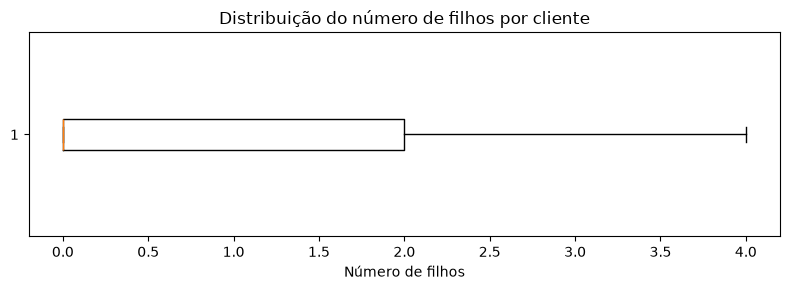

In [ ]:
%pip install matplotlib
import matplotlib.pyplot as plt

# Verifica possíveis outliers do número de filhos, considerando cada cliente uma vez
plt.figure(figsize=(8, 3))

plt.boxplot(
    df_clientes["CL_FHL"].dropna(),
    vert=False,
    whis=1.5
)

plt.title("Distribuição do número de filhos por cliente")
plt.xlabel("Número de filhos")
plt.tight_layout()
plt.show()

O gráfico demonstra que não há outliers no número de filhos. 

Seguindo essa linha, assim como a redundância na coluna número de filhos afeta as análises, podemos verificar outras. 

Uma compra pode conter vários produtos e categorias. Por isso, vou diferenciar registros, compras distintas e clientes distintos. 

In [ ]:
# Verifica a consistência do identificador de compra
consistencia_compras = df_limpo.groupby("CO_ID").agg(
    clientes=("CL_ID", "nunique"),
    datas=("DATA", "nunique"),
    generos=("CL_GENERO", "nunique")
)
compras_inconsistentes = consistencia_compras.gt(1).any(axis=1)

print("Compras com cliente, data ou gênero divergentes:", compras_inconsistentes.sum())
print("Total de compras distintas:", df_limpo["CO_ID"].nunique())
print("Total de clientes distintos:", df_limpo["CL_ID"].nunique())

if compras_inconsistentes.any():
    raise ValueError
    ("Existem compras inconsistentes. Revisar os identificadores antes dos agrupamentos.")

Compras com cliente, data ou gênero divergentes: 0
Total de compras distintas: 18471
Total de clientes distintos: 1000


In [ ]:
# Agrupa os registros por gênero e conta compras e clientes distintos
resumo_genero = (
    df_limpo.groupby("CL_GENERO")
    .agg(
        registros=("CO_ID", "size"),
        compras=("CO_ID", "nunique"),
        clientes=("CL_ID", "nunique")
    )
    .sort_values("compras", ascending=False)
)

resumo_genero["percentual_compras"] = (
    resumo_genero["compras"] / df_limpo["CO_ID"].nunique() * 100
)
resumo_genero["compras_por_cliente"] = resumo_genero["compras"] / resumo_genero["clientes"]

display(resumo_genero.round(2))

,registros,compras,clientes,percentual_compras,compras_por_cliente
CL_GENERO,,,,,
F,382427,9615,519,52.05,18.53
M,351020,8856,481,47.95,18.41


O gênero feminino possui mais compras na base: 9.615, contra 8.856 do gênero masculino. Porém, também há mais clientes do gênero Femininos (519 contra 481), o que não justifica a diferença, mas informa sobre um desbalanceamento de amostras referentes ao gênero.

Ao olhar as compras por cliente, os valores ficam próximos: aproximadamente 18,53 para mulheres e 18,41 para homens. Assim, a diferença nos totais, sozinha, não define nenhuma conclusão.

In [ ]:
# Agrupa os registros por categoria de produto
resumo_categoria = (
    df_limpo.groupby("PR_CAT")
    .agg(
        registros=("CO_ID", "size"),
        compras_com_categoria=("CO_ID", "nunique"),
        produtos_distintos=("PR_ID", "nunique")
    )
    .sort_values("registros", ascending=False)
)

resumo_categoria["percentual_registros"] = resumo_categoria["registros"] / len(df_limpo) * 100
resumo_categoria["percentual_compras_com_categoria"] = (
    resumo_categoria["compras_com_categoria"] / df_limpo["CO_ID"].nunique() * 100
)

display(resumo_categoria.round(2))

,registros,compras_com_categoria,produtos_distintos,percentual_registros,percentual_compras_com_categoria
PR_CAT,,,,,
ALIMENTOS,384197,18267,120,52.38,98.90
HIGIENE,137702,17610,43,18.77,95.34
LIMPEZA,128632,17475,40,17.54,94.61
BEBIDAS,38264,14735,12,5.22,79.77
PET,28553,13495,9,3.89,73.06
ACESSORIOS,12871,9224,4,1.75,49.94
NAO INFORMADO,3228,3228,1,0.44,17.48


A categoria ALIMENTOS concentra 384197 registros, aproximadamente 52,38% da base limpa, e aparece em 18.267 compras. Isso indica sua presença frequente nas compras registradas.

Uma mesma compra pode aparecer em várias categorias. Por isso, somar a coluna compras_com_categoria não resulta no total de compras distintas. Os 3228 registros com categoria não informada foram mantidos como um grupo separado.

- Sprint 5 (Relatório e Documentação)

In [ ]:
# Reúne os principais contadores da análise
relatorio_final = pd.Series({
    "registros_originais": len(df_varejo),
    "colunas_originais": df_varejo.shape[1],
    "colunas_vazias_removidas": len(colunas_vazias),
    "registros_sem_essenciais_removidos": registros_sem_essenciais,
    "duplicatas_removidas": duplicatas_removidas,
    "registros_limpos": len(df_limpo),
    "colunas_limpas": df_limpo.shape[1],
    "compras_distintas": df_limpo["CO_ID"].nunique(),
    "clientes_distintos": df_limpo["CL_ID"].nunique(),
    "registros_com_categoria_nao_informada": df_limpo["PR_CAT"].eq("NAO INFORMADO").sum(),
    "nulos_remanescentes": df_limpo.isna().sum().sum(),
    "duplicatas_remanescentes": df_limpo.duplicated().sum(),
}, name="quantidade")

print("Relatório final:")
display(relatorio_final)

Relatório final:


registros_originais                      830000
colunas_originais                            14
colunas_vazias_removidas                      4
registros_sem_essenciais_removidos            0
duplicatas_removidas                      96553
registros_limpos                         733447
colunas_limpas                               10
compras_distintas                         18471
clientes_distintos                         1000
registros_com_categoria_nao_informada      3228
nulos_remanescentes                           0
duplicatas_remanescentes                      0
Name: quantidade, dtype: int64

- Conclusões

    - A limpeza removeu quatro colunas totalmente vazias e 96553 linhas repetidas. A base ficou com 733.47 registros e 10 colunas, sem nulos ou duplicatas. 
    - Considerando cada cliente uma única vez, o número médio de filhos é 1,136, com mediana e moda iguais a zero, sem outliers. A média por registro é 1,146, mostrando o efeito de repetir clientes com mais registros de compras.
    - O gênero feminino possui o maior número de compras, com 9615 de um total de 18471. Porém, as compras por cliente são próximas entre feminino e masculino, então os totais precisam ser interpretados junto com a quantidade de clientes.
    - A categoria ALIMENTOS concentra aproximadamente 52,38% dos registros limpos. A base permite analisar presença de produtos nas compras, mas não faturamento ou unidades vendidas, pois faltam preço e quantidade.
    - Permanecem 3228 registros com categoria e nome do produto não informados. O preenchimento com NAO INFORMADO preserva esses registros e sinaliza a ausência.

- Exportação da base limpa e dos resumos

Vou salvar a base tratada e os resultados em CSV, usando ponto e vírgula como separador e sem incluir o índice da tabela como uma coluna extra. Na base exportada, a data será gravada como AAAA-MM-DD.

In [ ]:
from pathlib import Path

# Exporta a base limpa para a mesma pasta do notebook
df_limpo.to_csv("df_limpo.csv", sep=";", index=False, date_format="%Y-%m-%d", encoding="utf-8")

# Salva os resultados para consulta e conferência posterior
pasta_resultados = Path("resultados")
pasta_resultados.mkdir(exist_ok=True)

resumo_nulos.to_csv(pasta_resultados / "nulos_originais.csv", sep=";", index_label="coluna")
estatisticas_registros.join(estatisticas_clientes).to_csv(
    pasta_resultados / "estatisticas_filhos.csv", sep=";", index_label="estatistica"
)
pd.DataFrame({
    "unidade": ["por_registro", "por_cliente"],
    "modas": [str(modas_registros), str(modas_clientes)]
}).to_csv(pasta_resultados / "modas_filhos.csv", sep=";", index=False)
resumo_genero.to_csv(pasta_resultados / "resumo_genero.csv", sep=";")
resumo_categoria.to_csv(pasta_resultados / "resumo_categoria.csv", sep=";")
relatorio_final.to_csv(pasta_resultados / "relatorio_final.csv", sep=";", index_label="indicador")

print("Base limpa salva em df_limpo.csv")
print("Resumos salvos na pasta resultados")

Base limpa salva em df_limpo.csv
Resumos salvos na pasta resultados
